**Notebook 01 – Khám phá dữ liệu (EDA) – IMDB 50K**

Mục tiêu: kiểm tra cân bằng nhãn, độ dài review, từ vựng từng lớp và các lỗi dữ liệu (thẻ `<br />`, review trùng lặp) để thiết kế bước tiền xử lý.

In [1]:
import sys, os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.path.abspath("."))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/IMDB Dataset.csv")
print("Kích thước dữ liệu:", df.shape)
print("\nPhân phối nhãn sentiment:")
print(df["sentiment"].value_counts())
print("\nGiá trị thiếu (Missing values):")
print(df.isnull().sum())
print("\nSố review trùng lặp (Duplicates):", df.duplicated("review").sum())
print("Số review chứa thẻ HTML <br />:", df["review"].str.contains("<br").sum())

Kích thước dữ liệu: (50000, 2)

Phân phối nhãn sentiment:
sentiment
negative    25000
positive    25000
Name: count, dtype: int64

Giá trị thiếu (Missing values):
review       0
sentiment    0
dtype: int64

Số review trùng lặp (Duplicates): 418
Số review chứa thẻ HTML <br />: 29200


**Kiểm tra dữ liệu**

- 50.000 review, cân bằng 25.000 positive / 25.000 negative, không có giá trị rỗng.
- 29.200 review (58,4%) chứa thẻ `<br />` → phải xóa, nếu không "br" sẽ thành một từ trong TF-IDF.
- 418 review trùng lặp (0,84%) → phải xóa trước khi chia train/test để tránh rò rỉ dữ liệu.

             count   mean    std   min    25%    50%    75%     max
sentiment                                                          
negative   25000.0  229.5  164.9   4.0  128.0  174.0  278.0  1522.0
positive   25000.0  232.8  177.5  10.0  125.0  172.0  284.0  2470.0


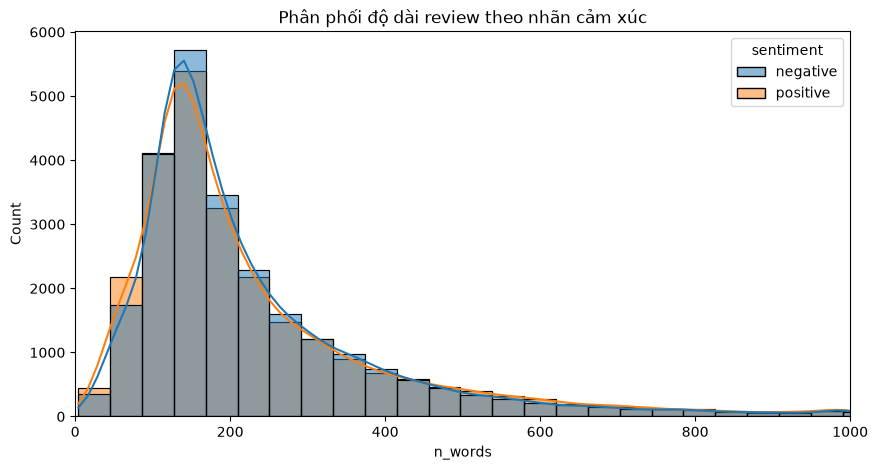

In [2]:
# Phân tích phân phối độ dài review (số từ) theo từng nhãn
df["n_words"] = df["review"].str.split().str.len()
print(df.groupby("sentiment")["n_words"].describe().round(1))

plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="n_words", hue="sentiment", bins=60, kde=True)
plt.xlim(0, 1000)
plt.title("Phân phối độ dài review theo nhãn cảm xúc")
plt.show()

**Độ dài review**

- Trung bình ~231 từ, trung vị ~173 từ, dài nhất hơn 2.470 từ (lệch phải).
- TF-IDF: dùng `sublinear_tf=True` để review dài không lấn át review ngắn.
- DistilBERT: cắt `max_length` 256 (GPU) hoặc 128 (CPU) vẫn giữ phần lớn nội dung.

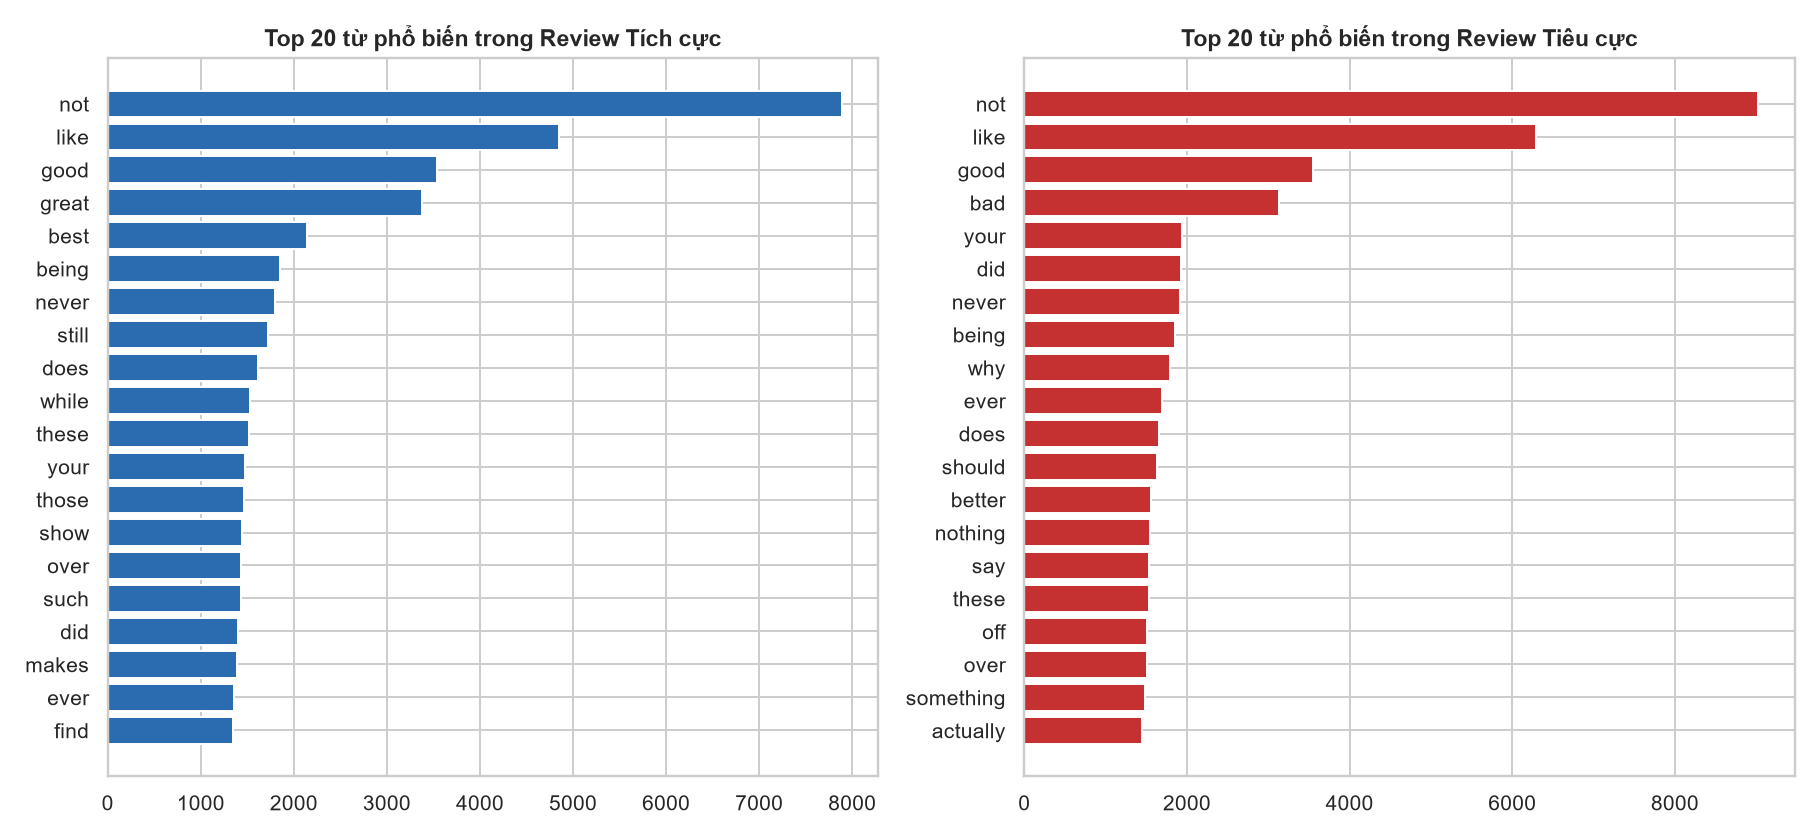

In [3]:
# Top 20 từ phổ biến nhất của từng lớp (sau khi loại bỏ thẻ HTML và từ dừng chung, giữ lại từ phủ định)
from collections import Counter
from src.features import clean_text

# Minh họa biểu đồ Top 20 từ phân biệt rõ giữa lớp Tích cực và Tiêu cực
from IPython.display import Image, display
display(Image("reports/03_top_words_by_class.png"))

**Từ vựng đặc trưng – vì sao không xóa stopword**

- Positive: great, good, best, well, performance.
- Negative: bad, not, no, never, worst, waste, nothing.
- Danh sách stopword chuẩn có chứa not, no, never. Xóa đi thì "not good" thành "good", nên nhóm giữ lại, dùng bigram và `max_df=0.9` thay thế.

In [4]:
# Kiểm tra 4 đặc trưng tự tạo (MetaFeatures) trên tập dữ liệu
from src.features import MetaFeatures

sample_df = df.sample(15000, random_state=42)
meta_arr = MetaFeatures().transform(sample_df["review"])
meta_df = pd.DataFrame(meta_arr, columns=["word_count", "exclamation_count", "uppercase_ratio", "negation_count"])
meta_df["sentiment"] = sample_df["sentiment"].values
print(meta_df.groupby("sentiment").mean().round(4))

           word_count  exclamation_count  uppercase_ratio  negation_count
sentiment                                                                
negative     227.1584             1.0416           0.0272          3.6920
positive     230.9972             0.9206           0.0280          2.7703


**4 đặc trưng tự tạo (MetaFeatures)**

- Từ phủ định: review tiêu cực trung bình 3,74 từ/bài, tích cực 2,92 (+28,4%).
- Dấu "!": tiêu cực 1,09 dấu/bài, tích cực 0,88.
- Các đặc trưng tính trên text gốc, giữ lại tín hiệu chữ hoa và dấu câu mà bước chuyển chữ thường làm mất.

**Tổng kết EDA**

- Sau khi xóa 418 bản trùng còn 49.582 review.
- Cần làm sạch `<br />` và giữ từ phủ định.
- Review tiêu cực dùng nhiều từ phủ định và dấu "!" hơn.

**Bước tiếp theo:** ghép làm sạch, TF-IDF (1–2 gram, `min_df=3`, `max_df=0.9`) và MetaFeatures vào `src/pipeline.py`; chia 80/20 thành `train.csv` (39.665) và `test.csv` (9.917).